<a href="https://colab.research.google.com/github/nisabulut/digital-image-processing/blob/main/5_1_Goruntu_%C4%B0sleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
!sudo apt-get update && sudo apt-get install -y libopencv-dev

Hit:1 https://cli.github.com/packages stable InRelease
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:5 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:7 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Hit:9 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:10 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu noble InRelease
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information...

In [11]:
%%writefile main.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <vector>

int main() {
    // 1. Görseli renkli olarak okuma
    std::string imagePath = "image";
    cv::Mat image = cv::imread(imagePath, cv::IMREAD_COLOR);

    if (image.empty()) {
        std::cerr << "Hata: Görsel yuklenemedi! Dosya yolunu kontrol edin." << std::endl;
        return -1;
    }

    // 2. Kanalları ayırma (B, G, R)
    std::vector<cv::Mat> bgrChannels;
    cv::split(image, bgrChannels);

    // 3. Histogram parametreleri
    int histSize = 256;
    float range[] = { 0, 256 };
    const float* histRange = { range };
    bool uniform = true;
    bool accumulate = false;

    cv::Mat bHist, gHist, rHist;

    // Her kanal için histogram hesaplama
    cv::calcHist(&bgrChannels[0], 1, 0, cv::Mat(), bHist, 1, &histSize, &histRange, uniform, accumulate);
    cv::calcHist(&bgrChannels[1], 1, 0, cv::Mat(), gHist, 1, &histSize, &histRange, uniform, accumulate);
    cv::calcHist(&bgrChannels[2], 1, 0, cv::Mat(), rHist, 1, &histSize, &histRange, uniform, accumulate);

    // 4. Histogram tuvali ve çizimi
    int histW = 512, histH = 400;
    int binW = cvRound((double)histW / histSize);

    cv::Mat histImage(histH, histW, CV_8UC3, cv::Scalar(255, 255, 255));

    cv::normalize(bHist, bHist, 0, histImage.rows, cv::NORM_MINMAX, -1, cv::Mat());
    cv::normalize(gHist, gHist, 0, histImage.rows, cv::NORM_MINMAX, -1, cv::Mat());
    cv::normalize(rHist, rHist, 0, histImage.rows, cv::NORM_MINMAX, -1, cv::Mat());

    for (int i = 1; i < histSize; i++) {
        cv::line(histImage,
                 cv::Point(binW * (i - 1), histH - cvRound(bHist.at<float>(i - 1))),
                 cv::Point(binW * (i), histH - cvRound(bHist.at<float>(i))),
                 cv::Scalar(255, 0, 0), 2);

        cv::line(histImage,
                 cv::Point(binW * (i - 1), histH - cvRound(gHist.at<float>(i - 1))),
                 cv::Point(binW * (i), histH - cvRound(gHist.at<float>(i))),
                 cv::Scalar(0, 255, 0), 2);

        cv::line(histImage,
                 cv::Point(binW * (i - 1), histH - cvRound(rHist.at<float>(i - 1))),
                 cv::Point(binW * (i), histH - cvRound(rHist.at<float>(i))),
                 cv::Scalar(0, 0, 255), 2);
    }

    // 5. Çıktıyı dosyaya kaydetme
    cv::imwrite("histogram_sonuc.png", histImage);
    std::cout << "Histogram basariyla 'histogram_sonuc.png' olarak kaydedildi." << std::endl;

    return 0;
}

Overwriting main.cpp


In [12]:
!g++ main.cpp -o program `pkg-config --cflags --libs opencv4`
!./program

Histogram basariyla 'histogram_sonuc.png' olarak kaydedildi.


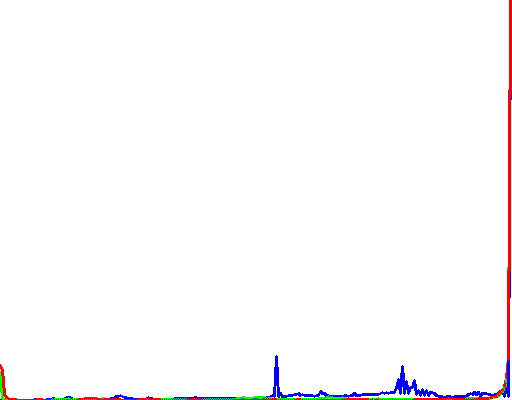

In [13]:
from IPython.display import Image
Image('histogram_sonuc.png')